<a href="https://colab.research.google.com/github/ArpitDoof/MLPracticeColabCS725/blob/main/LearningScikit_learn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [99]:
from sklearn.datasets import load_digits
import pandas as pd

In [47]:
X,y = load_digits(return_X_y = True)

In [48]:
X

array([[ 0.,  0.,  5., ...,  0.,  0.,  0.],
       [ 0.,  0.,  0., ..., 10.,  0.,  0.],
       [ 0.,  0.,  0., ..., 16.,  9.,  0.],
       ...,
       [ 0.,  0.,  1., ...,  6.,  0.,  0.],
       [ 0.,  0.,  2., ..., 12.,  0.,  0.],
       [ 0.,  0., 10., ..., 12.,  1.,  0.]])

In [49]:
y

array([0, 1, 2, ..., 8, 9, 8])

In [50]:
X.shape

(1797, 64)

In [51]:
y.shape

(1797,)

All Models in the scikit learn are python objects and learn = fit(X,y)

In [79]:
from sklearn.neighbors import  KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

In [53]:
#creating a model
mod = KNeighborsRegressor()

In [54]:
mod.fit(X,y)

KNeighborsRegressor()

In [55]:
mod.predict(X)

array([0., 1., 2., ..., 8., 9., 8.])

In [56]:
checkingans = mod.predict(X)
checkingans.shape

(1797,)

In [57]:
from sklearn.linear_model import LinearRegression

In [58]:
#mod = LinearRegression()

In [59]:
#mod.fit(X,y)

In [60]:
#mod.predict(X)

In [61]:
import matplotlib.pyplot as plt

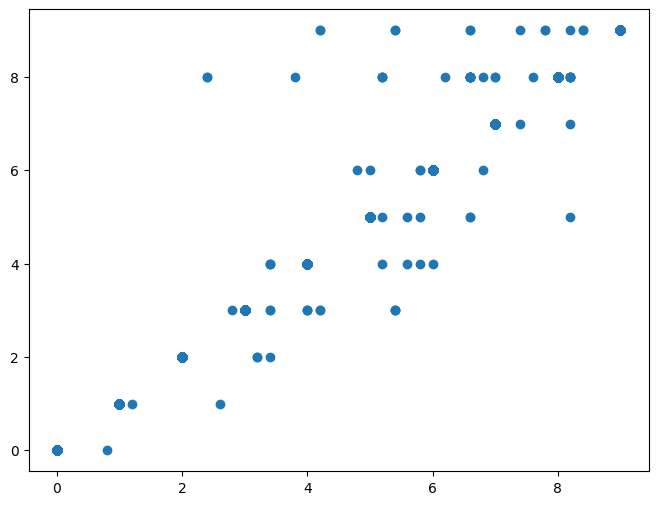

In [62]:
plt.figure(figsize = (8,6))
plt.scatter(checkingans,y)

In [75]:
 pipe = Pipeline([
     ("scaler",StandardScaler()),
     ("model", KNeighborsRegressor(n_neighbors=10))
 ])


In [76]:
pipe.fit(X,y)

Pipeline(steps=[('scaler', StandardScaler()),
                ('model', KNeighborsRegressor(n_neighbors=10))])

In [77]:
pipe.predict(X)

array([0. , 1. , 3.7, ..., 7.1, 8.9, 7. ])

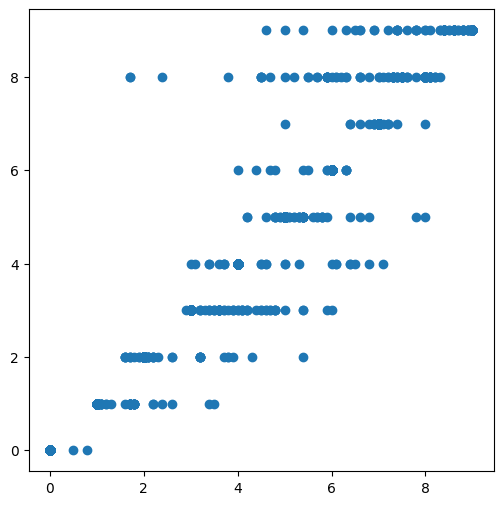

In [78]:
plt.figure(figsize=(6,6))
plt.scatter(pipe.predict(X),y)
plt.show()

In [80]:
pipe.get_params()

{'memory': None,
 'steps': [('scaler', StandardScaler()),
  ('model', KNeighborsRegressor(n_neighbors=10))],
 'transform_input': None,
 'verbose': False,
 'scaler': StandardScaler(),
 'model': KNeighborsRegressor(n_neighbors=10),
 'scaler__copy': True,
 'scaler__with_mean': True,
 'scaler__with_std': True,
 'model__algorithm': 'auto',
 'model__leaf_size': 30,
 'model__metric': 'minkowski',
 'model__metric_params': None,
 'model__n_jobs': None,
 'model__n_neighbors': 10,
 'model__p': 2,
 'model__weights': 'uniform'}

**now will do GridSearchCV takes the estimator which is the model we have created till now till pipeline and then we will pass the param_grid where we want to alter the number of n neighbours of KNeighboursRegressor and then do crossvalidation here using cv**

In [84]:
mod = GridSearchCV(
    estimator = pipe,
    param_grid = {"model__n_neighbors":[1,2,3,4,5,6,7,8,9,10]},
    cv = 3
)

In [85]:
mod.fit(X,y).predict(X)

array([0., 1., 2., ..., 8., 9., 8.])

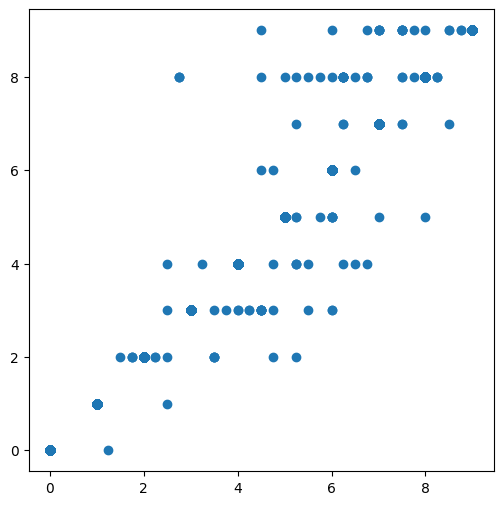

In [87]:
plt.figure(figsize=(6,6))
plt.scatter(mod.predict(X),y)
plt.show()

In [88]:
#there is a special function in the GridSearcCv i.e. cv_results_ which stores all the data and the performance of the data on that particular split and the numbe rof the nieghbour that we used



In [95]:
from sklearn.datasets import load_breast_cancer

<function load_breast_cancer at 0x7ae958193f60>


In [103]:
cancer = load_breast_cancer(as_frame=True)

In [105]:
df = cancer.frame

In [106]:
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [109]:
print(load_breast_cancer()['DESCR'])

.. _breast_cancer_dataset:

Breast cancer wisconsin (diagnostic) dataset
--------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 569

:Number of Attributes: 30 numeric, predictive attributes and the class

:Attribute Information:
    - radius (mean of distances from center to points on the perimeter)
    - texture (standard deviation of gray-scale values)
    - perimeter
    - area
    - smoothness (local variation in radius lengths)
    - compactness (perimeter^2 / area - 1.0)
    - concavity (severity of concave portions of the contour)
    - concave points (number of concave portions of the contour)
    - symmetry
    - fractal dimension ("coastline approximation" - 1)

    The mean, standard error, and "worst" or largest (mean of the three
    worst/largest values) of these features were computed for each image,
    resulting in 30 features.  For instance, field 0 is Mean Radius, field
    10 is Radius SE, field 20 is Worst Radius.

    - 